<a href="https://colab.research.google.com/github/jacquelineevu/projects/blob/main/flower_recognition%20using%20CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Flower Recognition Using Convolutional Neural Network

In [4]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import zipfile
import os
import keras
from keras.preprocessing import image
from tensorflow.keras import layers
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

In [6]:
import kagglehub

path = kagglehub.dataset_download("alxmamaev/flowers-recognition")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Path to dataset files: /kaggle/input/flowers-recognition


In [7]:
import os

print("Contents of downloaded path:", os.listdir(path))

dataset_dir = path
if 'flowers' in os.listdir(path):
    dataset_dir = os.path.join(path, 'flowers')
    if 'flowers' in os.listdir(dataset_dir):
        dataset_dir = os.path.join(dataset_dir, 'flowers')

print("Target dataset directory:", dataset_dir)
print("Flower categories found:", os.listdir(dataset_dir))

Contents of downloaded path: ['flowers']
Target dataset directory: /kaggle/input/flowers-recognition/flowers
Flower categories found: ['dandelion', 'daisy', 'sunflower', 'tulip', 'rose']


In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.


In [10]:
train_datagen = ImageDataGenerator(rescale=1. / 255, shear_range=0.2,
                                   zoom_range=0.2, horizontal_flip=True,
                                   validation_split=0.2)

test_datagen = ImageDataGenerator(rescale=1. / 255,
                                  validation_split=0.2)

train_datagen = train_datagen.flow_from_directory(dataset_dir,
                                                  target_size=(
                                                      IMG_SIZE[0], IMG_SIZE[1]),
                                                  subset='training',
                                                  batch_size=BATCH_SIZE)
test_datagen = test_datagen.flow_from_directory(dataset_dir,
                                                target_size=(
                                                    IMG_SIZE[0], IMG_SIZE[1]),
                                                subset='validation',
                                                batch_size=BATCH_SIZE)

Found 3457 images belonging to 5 classes.
Found 860 images belonging to 5 classes.


In [11]:
model = Sequential()
model.add(Conv2D(filters=64, kernel_size=(5, 5), padding='same',
                 activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))


model.add(Conv2D(filters=64, kernel_size=(3, 3),
                 padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))


model.add(Conv2D(filters=64, kernel_size=(3, 3),
                 padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

model.add(Conv2D(filters=64, kernel_size=(3, 3),
                 padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

model.add(Flatten())
model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dense(5, activation="softmax"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,541,253 (24.95 MB)

 Trainable params: 6,541,253 (24.95 MB)

 Non-trainable params: 0 (0.00 B)

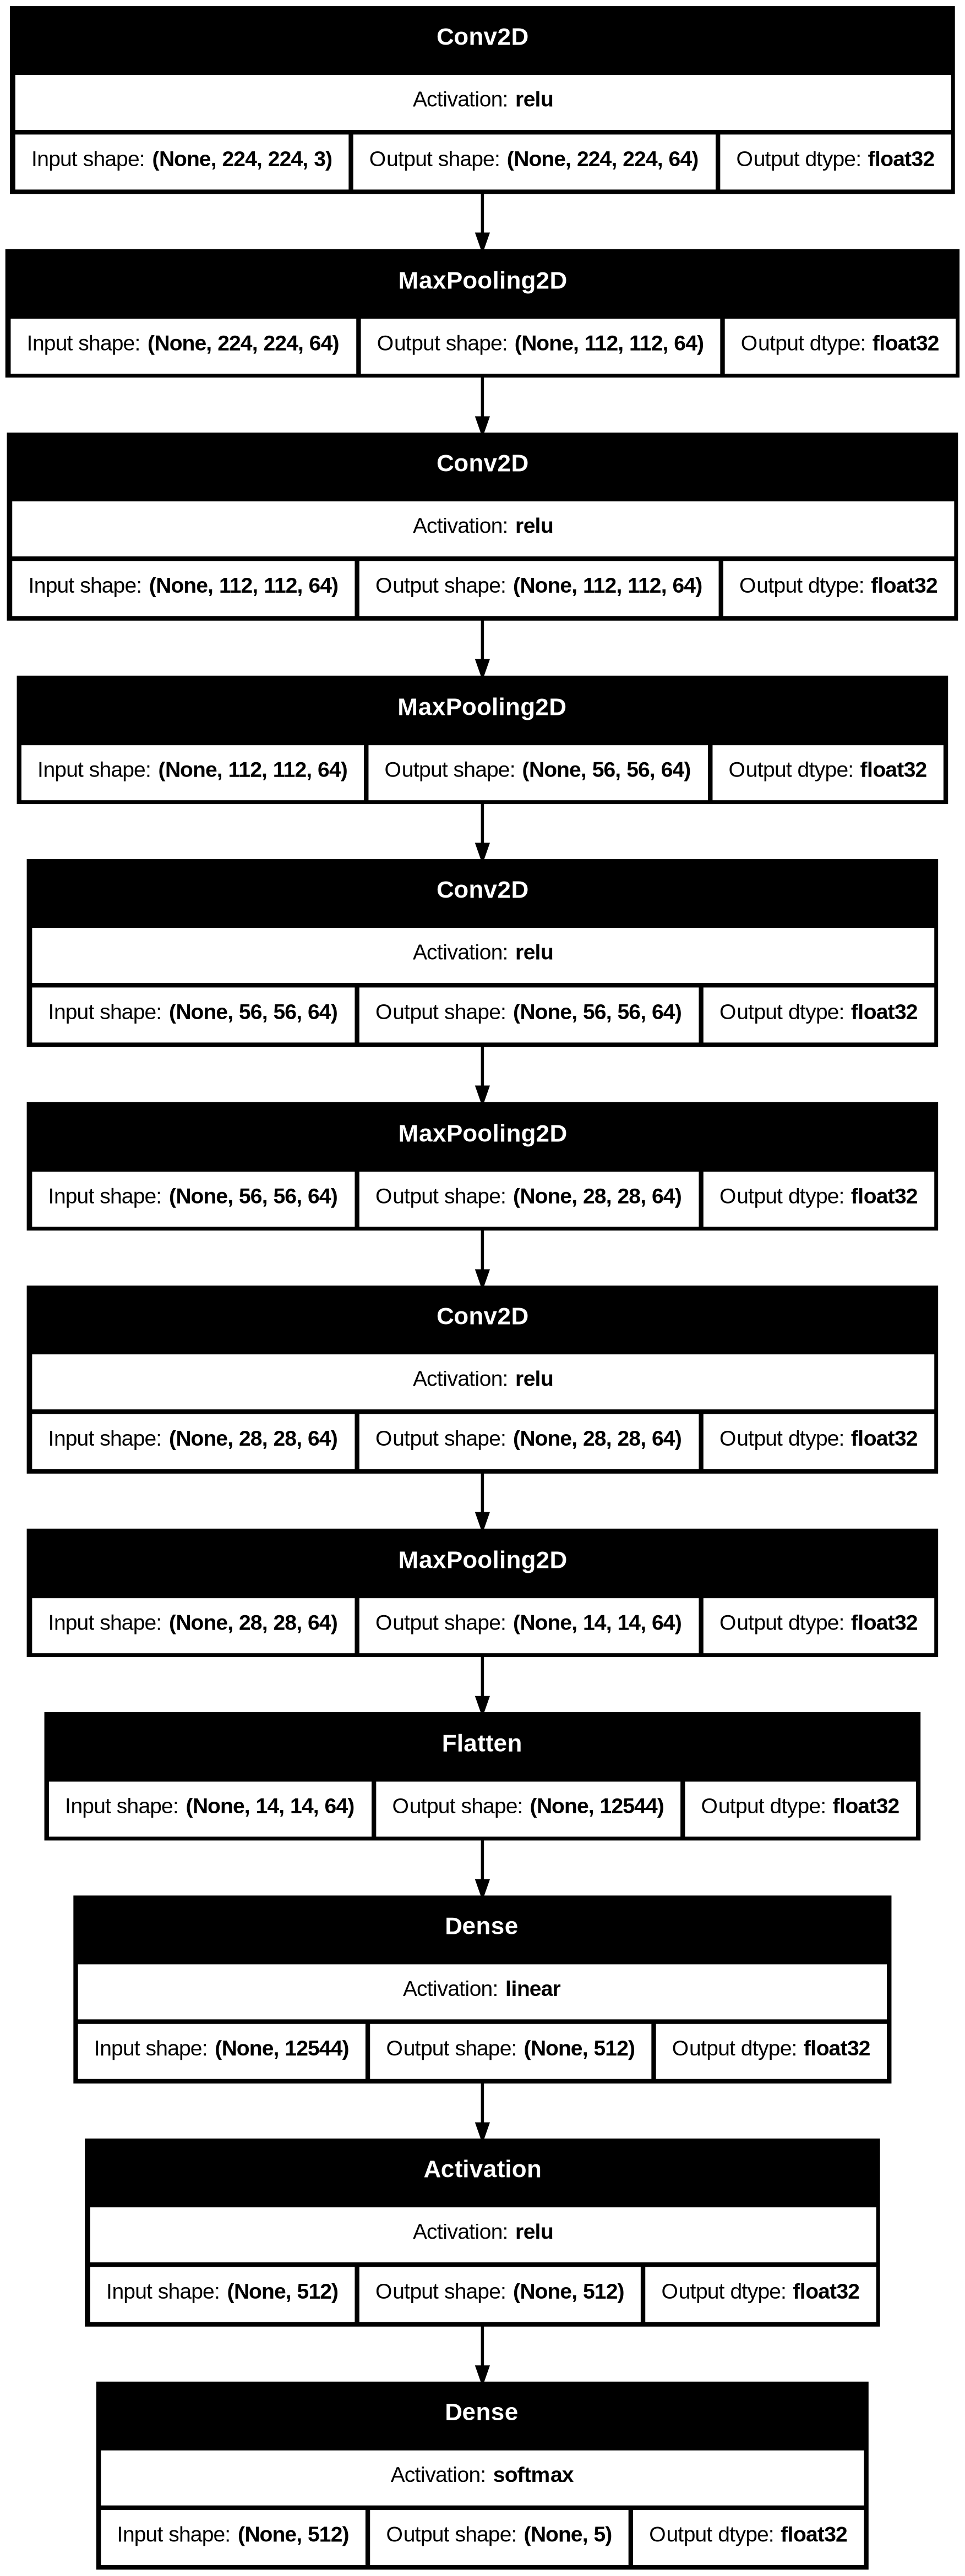

In [12]:
keras.utils.plot_model(
    model,
    show_shapes = True,
    show_dtype = True,
    show_layer_activations = True
)

In [13]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

epochs = 30
history = model.fit(train_datagen, epochs=epochs, validation_data=test_datagen)

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 686s 6s/step - accuracy: 0.4148 - loss: 1.3195 - val_accuracy: 0.5000 - val_loss: 1.2520
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 669s 6s/step - accuracy: 0.5409 - loss: 1.1174 - val_accuracy: 0.5512 - val_loss: 1.1200
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 666s 6s/step - accuracy: 0.6202 - loss: 0.9865 - val_accuracy: 0.6326 - val_loss: 0.9599
Epoch 4/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 670s 6s/step - accuracy: 0.6445 - loss: 0.9069 - val_accuracy: 0.6651 - val_loss: 0.8684
Epoch 5/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 681s 6s/step - accuracy: 0.6841 - loss: 0.8201 - val_accuracy: 0.6849 - val_loss: 0.8402
Epoch 6/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 671s 6s/step - accuracy: 0.7128 - loss: 0.7720 - val_accuracy: 0.6360 - val_loss: 0.9825
Epoch 7/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 671s 6s/step - accuracy: 0.6977 - loss: 0.7961 - val_accuracy: 0.6756 - val_loss: 0.8574
Epoch 8/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 705s 6s/step - accuracy: 0.7426 - loss: 0.6809 - val_accu

In [16]:
model.save('Model.h5')
savedModel=load_model('Model.h5')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
[[0. 0. 0. 1. 0.]]
sunflower


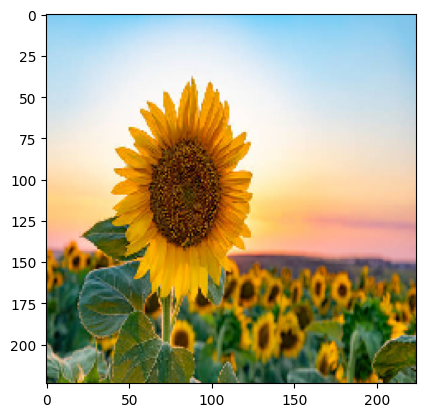

In [18]:
list_ = ['Daisy','Danelion','Rose','sunflower', 'tulip']

test_image = image.load_img('sunflower.jpg',target_size=(224,224))

plt.imshow(test_image)
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image,axis=0)

result = savedModel.predict(test_image)
print(result)

i=0
for i in range(len(result[0])):
  if(result[0][i]==1):
    print(list_[i])
    break